# Desenvolvimento do modelo de Regressão Logística
---

***A Fazeres:***
- Buscar `GridSearch`
- Buscar `Ensamble`
- Buscar `LaTeX`
- Buscar `overleaf.com`

A `Regressão Logística` é um algoritmo fundamental de aprendizado supervisionado utilizado para problemas de classificação, apesar de carregar "regressão" no nome.

Diferente da Regressão Linear, que prevê números contínuos, a Regressão Logística prevê a probabilidade de uma amostra pertencer a uma classe específica (geralmente binária, como `Sim` e `Não` ou `0` e `1`).

Utiliza de:

- O algoritmo utiliza a `Função Logística` (ou `Sigmóide`) para "achatar" qualquer valor numérico em um intervalo entre 0 e 1.
- Define-se um limiar (geralmente 0,5). Se a probabilidade calculada for maior que 0,5, o modelo classifica como classe A; se for menor, como classe B.

Uso em `Machine Learning`:

- `Classificação Binária`: É o uso mais comum. Exemplos incluem detecção de spam, diagnóstico médico, aprovação de crédito e no caso deste projeto, determinar a probabilidade de ser um ataque cibernético.

- `Base para Modelos Complexos`: É frequentemente usada como um baseline (modelo de referência inicial) devido à sua simplicidade e rapidez.

- `Interpretabilidade`: Em Machine Learing, é muito valorizada porque permite entender o peso de cada variável na decisão final (quão importante cada característica é para a probabilidade).


Principais fórmulas estatísticas:

1. `Equação Linear (Logit)`:

   Antes de chegar à probabilidade, o modelo calcula um valor intermediário ($z$), que é uma combinação linear dos atributos (features) do seu conjunto de dados:

   <div style="text-align: center;">
      <img src="../../imagens/logit.png" width="480">
   </div>


2. `Função Sigmóide (Função Logística)`:
  
   Para converter esse valor `z` (que pode ir de `-infinito` a `+infinto`) em uma probabilidade `P` entre 0 e 1, utiliza-se a `função sigmóide`:

    <div style="text-align: center;">
      <img src="../../imagens/funcao_sigmoide.png" width="480">
    </div>

3. `Função de Custo (Log Loss / Entropia Cruzada)`:

Não se usa o `Erro Quadrático Médio` (como na regressão linear) porque a `sigmóide` tornaria a função não-convexa. Usa-ses `Log Loss`:

<div style="text-align: center;">
  <img src="../../imagens/log_loss.png" width="480">
</div>

4. `Razão de Chances (Odds Ratio)`:

    A `Regressão Logística` também pode ser expressa em termos de `odds (chances)`, que é a razão entre a probabilidade de sucesso e a de fracasso:

<div style="text-align: center;">
  <img src="../../imagens/odds_ratio.png" width="480">
</div>

Esse notebook mostra o desenvolvimento, de maneira explicada, de um `LogisticRegression`. Trará aplicações de `RFE`, limiares relativos à `Sensibilidade`, `Precisão` e `Equilíbrio`.

Serão teinados quatro modelos com arquitetura em funil:
- Categoria 1:

- Categoria 2:


Será usado `GridSearchCV` para eleger um modelo campeão de cada uma das categorias. Ao final, os campeões terão suas características analisadas.

## A) Importando as Bibliotecas e Pacotes a serem usados
---

### 1. Pacotes baixados
---

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, PredefinedSplit
from xgboost import XGBClassifier

### 2. Pacotes Predexan
---

In [2]:
import sys
import os

caminho_predexan = os.path.abspath(os.path.join(os.getcwd(), '../..'))

if caminho_predexan not in sys.path:
    sys.path.append(caminho_predexan)

print(f"Pastas encontradas: {os.listdir(caminho_predexan)}")

import predexan.graficos as pg
import predexan.metricas as pm
import predexan.preproc as pp

Pastas encontradas: ['.ipynb_checkpoints', 'analise_exploratoria_pre_processamento', 'dataset', 'imagens', 'modelos', 'predexan', 'README.md']


## B) Determinando os Dataframes à partir das bases de dados pré-processados
---

### 1. Determinando df_treino
---

In [3]:
df_treino = pd.read_parquet('../../dataset/pre_processado/treino_pre_processado.parquet')
df_treino.info()

<class 'pandas.DataFrame'>
Index: 96822 entries, 0 to 175337
Data columns (total 59 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 96822 non-null  float64
 1   num_pacotes_origem                  96822 non-null  float64
 2   num_pacotes_destino                 96822 non-null  float64
 3   total_bytes_origem                  96822 non-null  float64
 4   total_bytes_destino                 96822 non-null  float64
 5   taxa_pacote                         96822 non-null  float64
 6   carga_origem                        96822 non-null  float64
 7   carga_destino                       96822 non-null  float64
 8   pacotes_perdidos_origem             96822 non-null  float64
 9   pacotes_perdidos_destino            96822 non-null  float64
 10  tempo_medio_pacote_origem           96822 non-null  float64
 11  bytes_por_pacote_destino            96822 non-null  floa

### 2. Determinando df_teste
---

In [4]:
df_teste = pd.read_parquet('../../dataset/pre_processado/teste_pre_processado.parquet')
df_teste.info()

<class 'pandas.DataFrame'>
Index: 49971 entries, 0 to 82328
Data columns (total 57 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   duracao_conexao_seg                 49971 non-null  float64
 1   num_pacotes_origem                  49971 non-null  float64
 2   num_pacotes_destino                 49971 non-null  float64
 3   total_bytes_origem                  49971 non-null  float64
 4   total_bytes_destino                 49971 non-null  float64
 5   taxa_pacote                         49971 non-null  float64
 6   carga_origem                        49971 non-null  float64
 7   carga_destino                       49971 non-null  float64
 8   pacotes_perdidos_origem             49971 non-null  float64
 9   pacotes_perdidos_destino            49971 non-null  float64
 10  tempo_medio_pacote_origem           49971 non-null  float64
 11  bytes_por_pacote_destino            49971 non-null  float

## C) Separando os valores em teste e treino
---

Nessa seção, serão separadas as `features` do `target`, tanto para a base de testes quanto de treino.

Há duas possibilidades claras de `target`, presentes nos datasets, dado o cenário de `Classificação` e `Regressão Logística`: `label`e `categoria_ataque.

A primeira retornaria um diagnóstico apontado se há uma probabilidade alta ou baixa de haver um ataque, de maneira geral. Já a segunda, retornaria a probabilidade de haver um ataque específico dentro de suas dez classes.

A escolha do target se embasa tanto na especialização da resposta, quanto no desempenho e custo computacional do modelo. Dessa forma, ao escolher `label`, a resposta é mais simples, mas continua sendo de grande valor, e o custo computacional é muito inferior. Já a escolha de `categoria_ataque`, traz uma resposta mais especializada e de maior qualidade para o usuário, contudo o custo computacional se mostrou alto.

### 1. Atributos do df_treino
---

In [5]:
# Features
X_treino = df_treino.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_treino é {type(X_treino)}. Possui {X_treino.shape[1]} features e {X_treino.shape[0]} registros.')
# Target
y_treino = df_treino['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_treino é {type(y_treino)}')

O tipo de X_treino é <class 'pandas.DataFrame'>. Possui 47 features e 96822 registros.
O tipo de y_treino é <class 'pandas.Series'>


### 2. Atributos do df_teste
---

In [6]:
# Features
X_teste = df_teste.drop(columns=['label_0', 
                                   'label_1',
                                   'categoria_ataque_Analysis',
                                   'categoria_ataque_Backdoor',
                                   'categoria_ataque_DoS',
                                   'categoria_ataque_Exploits',
                                   'categoria_ataque_Fuzzers',
                                   'categoria_ataque_Generic',
                                   'categoria_ataque_Normal',
                                   'categoria_ataque_Reconnaissance',
                                   'categoria_ataque_Shellcode',
                                   'categoria_ataque_Worms'
                                  ])
print(f'O tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')
# Target
y_teste = df_teste['label_1'] # Escolhendo somente uma, no caso a de ataque, se torna classificação binária
print(f'O tipo de y_teste é {type(y_teste)}')

O tipo de X_teste é <class 'pandas.DataFrame'>. Possui 45 features e 49971 registros.
O tipo de y_teste é <class 'pandas.Series'>


O dataset de teste possui duas features a menos: `servico_conexao_pop3` e `servico_conexao_ssh`. Desta forma, é necessário adicionar ambas, com os valores iguais a `0.0`:

In [7]:
X_teste = X_teste.reindex(columns=X_treino.columns, fill_value=0.0)

print(f'Agora, o tipo de X_teste é {type(X_teste)}. Possui {X_teste.shape[1]} features e {X_teste.shape[0]} registros.')

Agora, o tipo de X_teste é <class 'pandas.DataFrame'>. Possui 47 features e 49971 registros.


## D) Desenvolvimento dos Modelos de XGBoost de Classificação sem a aplicação do RFE
---

### 1. Aplicação do PredefinedSplit usando X_treino
---

In [8]:
limite = int(len(X_treino) * 0.8)

# -1 indica dados de treino | 0 indica dados de validação
indices_validacao = np.zeros(X_treino.shape[0])
indices_validacao[:limite] = -1  # Treino
indices_validacao[limite:] = 0   # Validação

# Divisor customizado
pds = PredefinedSplit(test_fold=indices_validacao)

### 2. Criação do modelo base
---

In [9]:
# Grid Search passando o 'pds' no lugar do 'cv'(Cross-Validation)
rl_base = LogisticRegression(random_state=42, 
                             max_iter=5000, 
                             solver='saga', 
                             penalty='elasticnet',
                             class_weight='balanced')

#### 2.1. Explicação dos hiperparâmetros
---

- `random_state=42`: Garante a `reprodutibilidade`. Ele fixa o algoritmo de aleatoriedade para que, toda vez que o código for rodado, o modelo chegue exatamente ao mesmo resultado.

- `max_iter=3000`: É o número máximo de iterações que o algoritmo tem para encontrar os melhores pesos. Valores altos como 3000 ajudam o modelo a convergir (chegar na resposta final) em datasets complexos.

- `solver='saga'`: É o "motor" matemático que otimiza o modelo. O saga é uma boa escolha para datasets grandes e é o único que suporta todas as penalidades.

- `penalty='elasticnet'`: É um tipo de regularização "híbrida". Ela combina o `L1` (que pode zerar coeficientes inúteis, selecionando variáveis) e o `L2` (que apenas diminui os pesos para evitar extremos).

- `l1_ratio=0.5`: Como `elasticnet` foi a penalidade escolhida, este parâmetro define o uso de `L1` e `L2`. 0.5 significa que você está usando 50% de `L1` e 50% de `L2`.

- `C=5.0`: Controla a força da regularização. Funciona ao inverso: valores menores de `C` aplicam uma regularização mais forte. Um C=5.0 é considerado alto. Isto significa que está se confiando muito nos dados de treino e aplicando uma penalidade mais leve.

### 3. Definição dos parâmetros e instanciação da classe GridSearchCV 
---

In [10]:
parametros = {'l1_ratio': [0.2, 0.5, 0.8],
             'C': [0.1, 1.0, 10.0]}

#### 3.1. Explicação dos hiperparâmetros
---

In [11]:
# cv=pds vai rodar apenas uma vez cada arquitetura
grid_search = GridSearchCV(estimator=rl_base, param_grid=parametros, cv=pds, n_jobs=4, verbose=2)

- `estimator=mlp_base`: define o algoritmo base que será testado. No caso, indica que o Grid Search aplicará as combinações de parâmetros em cima da estrutura da Rede Neural Multi-Layer Perceptron (MLPClassifier).
- `param_grid=parametros`: o dicionário de busca que contém a grade de opções. Se o dicionário testar, por exemplo, 3 arquiteturas de camadas ocultas e 3 taxas de aprendizado diferentes, o Grid Search multiplicará essas opções para testar de forma exaustiva todas as $3 \times 3 = 9$ combinações possíveis.
- `cv=pds`: estratégia de validação cruzada (Cross-Validation). O pds (objeto PredefinedSplit) indica que os conjuntos de dados de treino e teste/validação já possuem uma divisão fixa pré-definida. Isso faz com que cada arquitetura seja executada apenas uma vez em vez de rodar o padrão de 5 vezes (5-fold), economizando tempo de processamento e respeitando a divisão original do dataset UNSW-NB15.
- `n_jobs=4`: define o nível de paralelismo do processo de busca. Ao configurar o valor como 4, o Python instrui o processador a abrir 4 núcleos de processamento (threads) em paralelo. Isso permite que o computador treine até 4 redes neurais de uma só vez, reduzindo o tempo total do Grid Search em quase $4\times$

### 4. Treino dos modelos com GridSearchCV 
---

In [12]:
pm.imprimir_desempenho(grid_search.fit, X_treino, y_treino)

Fitting 1 folds for each of 9 candidates, totalling 9 fits

RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 29/05/2026 17:59:34

    1. TEMPO: 1396.7794s (23.28 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 40.28 MB
        - Diferença líquida de RAM no processo: -26.55 MB
        - Total RAM alocada para o processo: 333.98 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 26.1%

  Execução concluída em: 29/05/2026 18:22:51



GridSearchCV(cv=PredefinedSplit(test_fold=array([-1, -1, ...,  0,  0], shape=(96822,))),
             estimator=LogisticRegression(class_weight='balanced',
                                          max_iter=5000, penalty='elasticnet',
                                          random_state=42, solver='saga'),
             n_jobs=4,
             param_grid={'C': [0.1, 1.0, 10.0], 'l1_ratio': [0.2, 0.5, 0.8]},
             verbose=2)

### 5. Resultado e escolha do modelo campeão
---

In [13]:
print('\nResultado:')
print('\n - Melhor arquitetura encontrada:') 
print(f'1. l1_ratio = {grid_search.best_params_["l1_ratio"]}')
print(f'2. C = {grid_search.best_params_["C"]}')
print(f'\n - Acurácia na validação fixa: {grid_search.best_score_:.4f}')


Resultado:

 - Melhor arquitetura encontrada:
1. l1_ratio = 0.2
2. C = 0.1

 - Acurácia na validação fixa: 0.9286


In [14]:
modelo_campeao = grid_search.best_estimator_

### 6. Realização das Predições de Teste
---

#### 6.1. Predição Probababilística
---

Para a Predição Probabilística, é usado o método `predict_proba()` na seguinte expressão: `modelo_campeao.predict_proba(X_teste)`

In [15]:
y_predicao_probabilistica_1 = pm.imprimir_desempenho(modelo_campeao.predict_proba, X_teste)[:, 1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 29/05/2026 18:22:51

    1. TEMPO: 0.0253s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 18.69 MB
        - Diferença líquida de RAM no processo: 3.96 MB
        - Total RAM alocada para o processo: 338.10 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 20.8%

  Execução concluída em: 29/05/2026 18:22:51



#### 6.2. Predição Binária
---

Para a Predição Binária, é usado o método `predict()` na seguinte expressão: `modelo_campeao.predict(X_teste)`

In [16]:
y_predicao_binaria_1 = pm.imprimir_desempenho(modelo_campeao.predict, X_teste)


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 29/05/2026 18:22:51

    1. TEMPO: 0.0154s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 18.68 MB
        - Diferença líquida de RAM no processo: 0.38 MB
        - Total RAM alocada para o processo: 338.47 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 11.8%

  Execução concluída em: 29/05/2026 18:22:51



### 7. Desempenho do modelo
---

#### 7.1. Limiar Padrão (0.5)
---

##### 7.1.1. Matriz de Confusão
---

<Axes: >

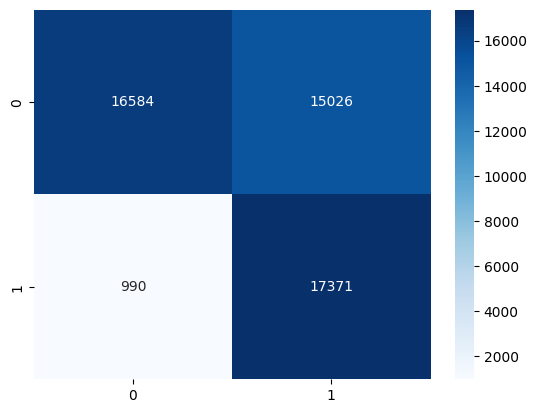

In [17]:
matriz_confusao_1 = confusion_matrix(y_teste, y_predicao_binaria_1)
sns.heatmap(matriz_confusao_1, annot=True, fmt='d', cmap='Blues')

##### 7.1.2. Relatório de Classificação
---

In [18]:
relatorio_classificacao_1 = classification_report(y_teste, y_predicao_binaria_1)
print(relatorio_classificacao_1)

              precision    recall  f1-score   support

         0.0       0.94      0.52      0.67     31610
         1.0       0.54      0.95      0.68     18361

    accuracy                           0.68     49971
   macro avg       0.74      0.74      0.68     49971
weighted avg       0.79      0.68      0.68     49971



##### 7.1.3. Curva ROC-AUC
---

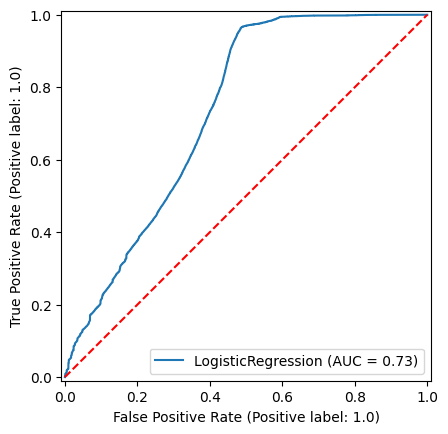

In [19]:
pg.gerar_roc_auc(modelo_campeao, X_teste, y_teste)

##### 7.1.4. Curva Precision-Recall
---

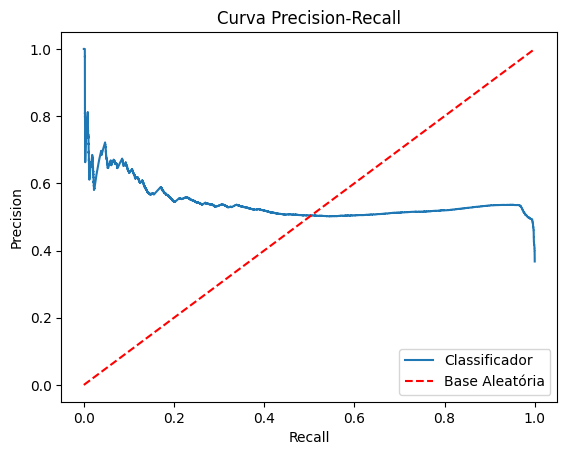

In [20]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica_1)

In [21]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica_1, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True)


 - Objetivo focado em Recall (meta = 95.0%)
      Limiar ideal a ser usado: 0.4914
      Recall real obtido: 95.00% (Ataques detectados)
      Precision real obtida: 53.59% (Acerto dos alertas disparados)

 - Objetivo focado em Precision (meta >= 95.0%)
      Limiar ideal a ser usado: 1.0000
      Recall real obtido: 0.24% (Ataques detectados)
      Precision real obtida: 95.65% (Acerto dos alertas disparados)

 - Equilíbrio Simétrico (Max F1-Score)
      Limiar ideal: 0.4642
      Recall neste ponto: 96.45% (Ataques detectados)
      Precision neste ponto: 53.53% (Acerto dos alertas)


#### 7.2. Limiar Equilibrado
---

##### 7.2.1. Matriz de Confusão
---

Limiar de equilíbrio do F1-Score entre Recall e Precision:

In [22]:
_, limiar_modelo_campeao, _ = pm.extrair_f1(y_teste, y_predicao_probabilistica_1)
print(limiar_modelo_campeao)

0.46423014795472745


In [23]:
y_predicao_probabilistica_equilibrada_1 = (y_predicao_probabilistica_1 > limiar_modelo_campeao).astype(int)

<Axes: >

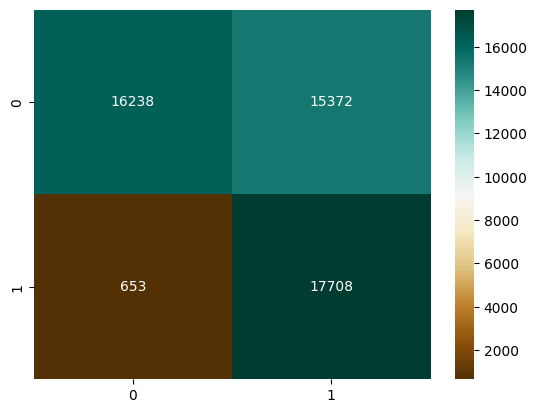

In [24]:
matriz_confusao_equilibrada_1 = confusion_matrix(y_teste, y_predicao_probabilistica_equilibrada_1)
sns.heatmap(matriz_confusao_equilibrada_1, annot=True, fmt='d', cmap='BrBG')

##### 7.2.2. Relatório de Classificação
---

In [25]:
relatorio_classificacao_equilibrado_1 = classification_report(y_teste, y_predicao_probabilistica_equilibrada_1)
print(relatorio_classificacao_equilibrado_1)

              precision    recall  f1-score   support

         0.0       0.96      0.51      0.67     31610
         1.0       0.54      0.96      0.69     18361

    accuracy                           0.68     49971
   macro avg       0.75      0.74      0.68     49971
weighted avg       0.80      0.68      0.68     49971



## E) Desenvolvimento dos Modelo de MLPs de Classificação de duas camadas com 20 features (RFE + XGBoost Classifier)
---

### 1. Aplicação do Recursive Feature Elimination (RFE) para diminuição da dimensionalidade
---

#### 1.1. Instanciamento da classe RFE
---

O objetivo é a diminuição da dimensionalidade, e a escolha das 20 features mais relevantes.

In [28]:
xgb_estimador = XGBClassifier(random_state=42, eval_metric='logloss')

In [29]:
seletor_rfe = RFE(estimator=xgb_estimador, n_features_to_select=20)

#### 1.2. Aplicação do RFE em X_treino
---

In [30]:
X_treino_reduzido = seletor_rfe.fit_transform(X_treino, y_treino)

In [31]:
colunas_originais = X_treino.columns
print(f'Registros e features de treino ANTES da aplicação do RFE:\n - Número de features e registros: {X_treino.shape}\n - Nomes das features: {X_treino.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do RFE:\n - Número de features e registros:  {X_treino_reduzido.shape} \n - Nomes das features: {list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do RFE:
 - Número de features e registros: (96822, 47)
 - Nomes das features: Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [32]:
type(X_treino_reduzido)

numpy.ndarray

In [33]:
X_treino_reduzido_df = pd.DataFrame(X_treino_reduzido, columns=colunas_selecionadas)
X_treino_reduzido_df.head()

,total_bytes_origem,total_bytes_destino,carga_origem,carga_destino,pacotes_perdidos_origem,pacotes_perdidos_destino,tempo_medio_pacote_origem,tamanho_janela_tcp_origem,rtt_handshake_tcp,tempo_syn_synack,tempo_synack_ack,tamanho_medio_pacotes_origem,tamanho_medio_pacotes_destino,protocolo_rede_outros,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp-data,servico_conexao_outros,estado_conexao_CON,estado_conexao_outros
0,-0.329992,-0.154433,-0.034939,-0.002418,-0.4,-0.333333,-0.054359,1.0,-0.009828,-0.016261,-0.004038,-0.547945,-0.274074,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,-0.131161,12.130358,-0.044014,0.808271,0.0,2.500000,0.269346,1.0,-0.009828,-0.016261,-0.004038,-0.424658,7.600000,0.0,0.0,1.0,0.0,0.0,0.0,0.0
2,-0.285714,3.666471,-0.054756,0.083443,-0.2,0.666667,2.568450,1.0,0.845333,0.898078,0.820533,-0.506849,5.511111,0.0,0.0,1.0,0.0,0.0,0.0,0.0
3,-0.175439,0.021139,-0.052917,-0.010829,-0.2,0.166667,1.570283,1.0,-0.009828,-0.016261,-0.004038,-0.424658,-0.118519,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,-0.214703,-0.126248,-0.043752,-0.009800,0.0,-0.166667,0.241995,1.0,0.971310,1.042226,0.931617,-0.410959,-0.259259,0.0,0.0,1.0,0.0,0.0,0.0,0.0


In [34]:
for feature in X_treino_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_treino_reduzido_df[feature].min()} a {X_treino_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_treino_reduzido_df[feature].max() - X_treino_reduzido_df[feature].min()}\n')


Feature TOTAL_BYTES_ORIGEM:

 - Amplitude: de -0.42606516290726815 a 5415.2819548872185

 - Magnitude: 5415.708020050126


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4302.6576629477395

 - Magnitude: 4302.862595419848


Feature CARGA_ORIGEM:

 - Amplitude: de -0.057231631081325486 a 9427.744951992034

 - Magnitude: 9427.802183623115


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 36.700989512499405

 - Magnitude: 36.717318415859594


Feature PACOTES_PERDIDOS_ORIGEM:

 - Amplitude: de -0.4 a 960.2

 - Magnitude: 960.6


Feature PACOTES_PERDIDOS_DESTINO:

 - Amplitude: de -0.3333333333333333 a 913.6666666666666

 - Magnitude: 914.0


Feature TEMPO_MEDIO_PACOTE_ORIGEM:

 - Amplitude: de -0.36133865318408365 a 1065.6872198364367

 - Magnitude: 1066.0485584896207


Feature TAMANHO_JANELA_TCP_ORIGEM:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature RTT_HANDSHAKE_TCP:

 - Amplitude: de -0.009828122445103204 a 19.24055182089483

 - Magnitu

#### 1.3. Aplicação do RFE em X_teste
---

In [35]:
X_teste_reduzido = seletor_rfe.transform(X_teste)

In [36]:
colunas_originais = X_teste.columns
print(f'Registros e features de treino ANTES da aplicação do PCA:\n - Número de features e registros: {X_teste.shape}\n - Nomes das features: {X_teste.columns}\n')
colunas_selecionadas = colunas_originais[seletor_rfe.support_]
print(f'\nRegistros e features de treino DEPOIS da aplicação do PCA:\n - Número de features e registros:  {X_teste_reduzido.shape} \n - Nomes das features: {list(colunas_selecionadas)}')

Registros e features de treino ANTES da aplicação do PCA:
 - Número de features e registros: (49971, 47)
 - Nomes das features: Index(['duracao_conexao_seg', 'num_pacotes_origem', 'num_pacotes_destino',
       'total_bytes_origem', 'total_bytes_destino', 'taxa_pacote',
       'carga_origem', 'carga_destino', 'pacotes_perdidos_origem',
       'pacotes_perdidos_destino', 'tempo_medio_pacote_origem',
       'bytes_por_pacote_destino', 'var_lat_pacotes_origem',
       'var_lat_pacotes_destino', 'tamanho_janela_tcp_origem',
       'num_sequencia_tcp_origem', 'num_sequencia_tcp_destino',
       'tamanho_janela_tcp_destino', 'rtt_handshake_tcp', 'tempo_syn_synack',
       'tempo_synack_ack', 'tamanho_medio_pacotes_origem',
       'tamanho_medio_pacotes_destino', 'profundidade_transacao_http',
       'tamanho_corpo_resposta_http', 'conexoes_recentes_ip_porta_destino',
       'conexoes_recentes_ip_porta_origem', 'ftp_autenticada',
       'num_comandos_ftp', 'num_metodos_http',
       'ip_porta_

In [37]:
type(X_teste_reduzido)

numpy.ndarray

In [38]:
X_teste_reduzido_df = pd.DataFrame(X_teste_reduzido, columns=colunas_selecionadas)
X_teste_reduzido_df.head()

,total_bytes_origem,total_bytes_destino,carga_origem,carga_destino,pacotes_perdidos_origem,pacotes_perdidos_destino,tempo_medio_pacote_origem,tamanho_janela_tcp_origem,rtt_handshake_tcp,tempo_syn_synack,tempo_synack_ack,tamanho_medio_pacotes_origem,tamanho_medio_pacotes_destino,protocolo_rede_outros,protocolo_rede_udp,servico_conexao_-,servico_conexao_ftp-data,servico_conexao_outros,estado_conexao_CON,estado_conexao_outros
0,-0.230576,-0.204932,283.916144,-0.016329,-0.4,-0.333333,-0.361200,0.0,-0.009828,-0.016261,-0.004038,2.260274,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1,0.298246,-0.204932,1387.032509,-0.016329,-0.4,-0.333333,-0.361238,0.0,-0.009828,-0.016261,-0.004038,10.931507,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0
2,0.008354,-0.204932,1345.152161,-0.016329,-0.4,-0.333333,-0.361275,0.0,-0.009828,-0.016261,-0.004038,6.178082,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0
3,-0.061821,-0.204932,944.612285,-0.016329,-0.4,-0.333333,-0.361263,0.0,-0.009828,-0.016261,-0.004038,5.027397,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0
4,0.450292,-0.204932,1338.854364,-0.016329,-0.4,-0.333333,-0.361212,0.0,-0.009828,-0.016261,-0.004038,13.424658,-0.592593,0.0,1.0,1.0,0.0,0.0,0.0,0.0


In [39]:
for feature in X_teste_reduzido_df.columns:
    print(f'\nFeature {feature.upper()}:')
    print(f'\n - Amplitude: de {X_teste_reduzido_df[feature].min()} a {X_teste_reduzido_df[feature].max()}')
    print(f'\n - Magnitude: {X_teste_reduzido_df[feature].max() - X_teste_reduzido_df[feature].min()}\n')


Feature TOTAL_BYTES_ORIGEM:

 - Amplitude: de -0.4277360066833751 a 5996.126148705096

 - Magnitude: 5996.55388471178


Feature TOTAL_BYTES_DESTINO:

 - Amplitude: de -0.20493247210804463 a 4303.239283617147

 - Magnitude: 4303.444216089255


Feature CARGA_ORIGEM:

 - Amplitude: de -0.057231631081325486 a 8294.141531483323

 - Magnitude: 8294.198763114404


Feature CARGA_DESTINO:

 - Amplitude: de -0.016328903360192524 a 34.078326484587734

 - Magnitude: 34.094655387947924


Feature PACOTES_PERDIDOS_ORIGEM:

 - Amplitude: de -0.4 a 1063.4

 - Magnitude: 1063.8000000000002


Feature PACOTES_PERDIDOS_DESTINO:

 - Amplitude: de -0.3333333333333333 a 917.5

 - Magnitude: 917.8333333333334


Feature TEMPO_MEDIO_PACOTE_ORIGEM:

 - Amplitude: de -0.36133865318408365 a 757.8754070510212

 - Magnitude: 758.2367457042053


Feature TAMANHO_JANELA_TCP_ORIGEM:

 - Amplitude: de 0.0 a 1.0

 - Magnitude: 1.0


Feature RTT_HANDSHAKE_TCP:

 - Amplitude: de -0.009828122445103204 a 29.195324055790017

 

### 2. Aplicação do PredefinedSplit usando X_treino_reduzido_df
---

In [40]:
limite = int(len(X_treino_reduzido_df) * 0.8)

indices_validacao = np.zeros(X_treino_reduzido.shape[0])
indices_validacao[:limite] = -1  # Treino
indices_validacao[limite:] = 0   # Validação

pds_rfe = PredefinedSplit(test_fold=indices_validacao)

### 3. Criação do modelo base RFE
---

In [41]:
rl_base_rfe = LogisticRegression(random_state=42, 
                             max_iter=5000, 
                             solver='saga', 
                             penalty='elasticnet',  
                             class_weight='balanced')

### 4. Definição dos parâmetros e instanciação da classe GridSearchCV 
---

In [42]:
parametros = {'l1_ratio': [0.2, 0.5, 0.8],
             'C': [0.1, 1.0, 10.0]}

In [43]:
# Trocamos cv=5 por cv=pds. Agora ele vai rodar APENAS 1 VEZ cada arquitetura!
grid_search_rfe = GridSearchCV(estimator=rl_base_rfe, param_grid=parametros, cv=pds_rfe, n_jobs=4, verbose=2)

### 5. Treino dos modelos com GridSearchCV 
---

In [44]:
pm.imprimir_desempenho(grid_search_rfe.fit, X_treino_reduzido_df, y_treino)

Fitting 1 folds for each of 9 candidates, totalling 9 fits

RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 29/05/2026 18:24:14

    1. TEMPO: 801.9530s (13.37 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 20.21 MB
        - Diferença líquida de RAM no processo: -2.29 MB
        - Total RAM alocada para o processo: 408.80 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 30.3%

  Execução concluída em: 29/05/2026 18:37:36



GridSearchCV(cv=PredefinedSplit(test_fold=array([-1, -1, ...,  0,  0], shape=(96822,))),
             estimator=LogisticRegression(class_weight='balanced',
                                          max_iter=5000, penalty='elasticnet',
                                          random_state=42, solver='saga'),
             n_jobs=4,
             param_grid={'C': [0.1, 1.0, 10.0], 'l1_ratio': [0.2, 0.5, 0.8]},
             verbose=2)

### 6. Resultado e escolha do modelo campeão
---

In [45]:
print('\nResultado:')
print('\n - Melhor arquitetura encontrada:') 
print(f'1. l1_ratio = {grid_search_rfe.best_params_["l1_ratio"]}')
print(f'2. C = {grid_search_rfe.best_params_["C"]}')
print(f'\n - Acurácia na validação fixa: {grid_search_rfe.best_score_:.4f}')


Resultado:

 - Melhor arquitetura encontrada:
1. l1_ratio = 0.5
2. C = 0.1

 - Acurácia na validação fixa: 0.9215


In [46]:
modelo_campeao_rfe = grid_search_rfe.best_estimator_

### 7. Realização das Predições de Teste
---

#### 7.1. Predição Probababilística
---

In [47]:
y_predicao_probabilistica_2 = pm.imprimir_desempenho(modelo_campeao_rfe.predict_proba, X_teste_reduzido_df)[:, 1]


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 29/05/2026 18:37:36

    1. TEMPO: 0.0119s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 1.53 MB
        - Diferença líquida de RAM no processo: 1.36 MB
        - Total RAM alocada para o processo: 410.25 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 50.0%

  Execução concluída em: 29/05/2026 18:37:36



#### 7.2. Predição Binária
---

In [48]:
y_predicao_binaria_2 = pm.imprimir_desempenho(modelo_campeao_rfe.predict, X_teste_reduzido_df)


RELATÓRIO DE DESEMPENHO DE PROCESSAMENTO:

  Execução iniciada em: 29/05/2026 18:37:36

    1. TEMPO: 0.0066s (0.00 min)

    2. MEMÓRIA RAM (Processo Atual):
        - Pico de processamento: 1.15 MB
        - Diferença líquida de RAM no processo: 0.39 MB
        - Total RAM alocada para o processo: 410.64 MB

    3. CPU:
        - Uso de CPU do sistema durante a execução: 0.0%

  Execução concluída em: 29/05/2026 18:37:36



### 8. Desempenho do modelo
---

#### 8.1. Limiar Padrão (0.5)
---

##### 8.1.1. Matriz de Confusão
---

<Axes: >

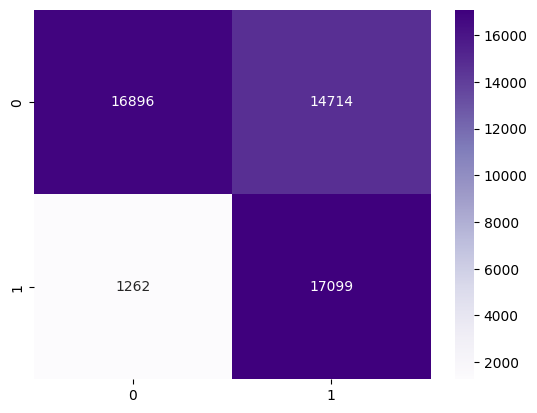

In [49]:
matriz_confusao_2 = confusion_matrix(y_teste, y_predicao_binaria_2)
sns.heatmap(matriz_confusao_2, annot=True, fmt='d', cmap='Purples')

##### 8.1.2. Relatório de Classificação
---

In [50]:
relatorio_classificacao_2 = classification_report(y_teste, y_predicao_binaria_2)
print(relatorio_classificacao_2)

              precision    recall  f1-score   support

         0.0       0.93      0.53      0.68     31610
         1.0       0.54      0.93      0.68     18361

    accuracy                           0.68     49971
   macro avg       0.73      0.73      0.68     49971
weighted avg       0.79      0.68      0.68     49971



##### 8.1.3. Curva ROC-AUC
---

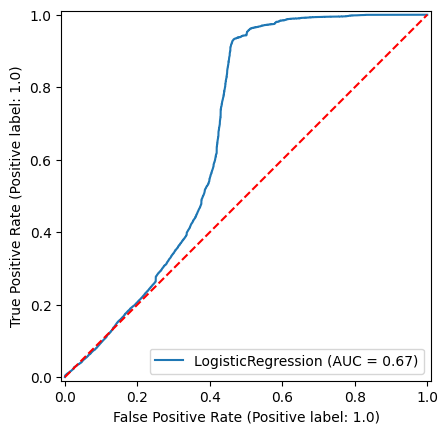

In [51]:
pg.gerar_roc_auc(modelo_campeao_rfe, X_teste_reduzido_df, y_teste)

##### 8.1.4. Curva Precision-Recall
---

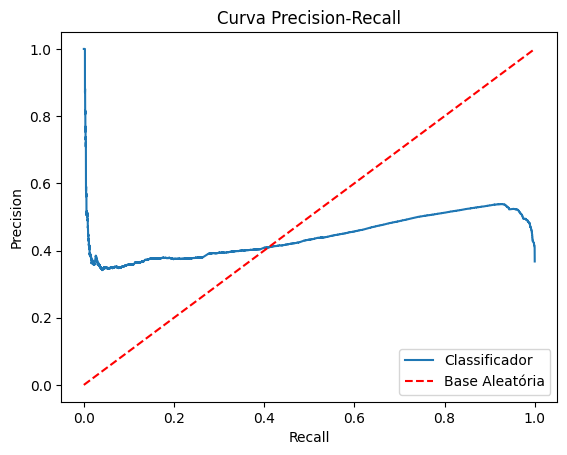

In [52]:
pg.gerar_curva_pr(y_teste, y_predicao_probabilistica_2)

In [53]:
pm.imprimir_prt(y_teste, y_predicao_probabilistica_2, obj_recall=True, meta_recall=0.95, obj_precision=True, meta_precision=0.95, obj_f1=True)


 - Objetivo focado em Recall (meta = 95.0%)
      Limiar ideal a ser usado: 0.4841
      Recall real obtido: 95.00% (Ataques detectados)
      Precision real obtida: 52.35% (Acerto dos alertas disparados)

 - Objetivo focado em Precision (meta >= 95.0%)
      Limiar ideal a ser usado: 1.0000
      Recall real obtido: 0.26% (Ataques detectados)
      Precision real obtida: 95.92% (Acerto dos alertas disparados)

 - Equilíbrio Simétrico (Max F1-Score)
      Limiar ideal: 0.4997
      Recall neste ponto: 93.22% (Ataques detectados)
      Precision neste ponto: 53.76% (Acerto dos alertas)


#### 8.2. Limiar Equilibrado
---

##### 8.2.1. Matriz de Confusão
---

Limiar de equilíbrio do F1-Score entre Recall e Precision:

In [54]:
_, limiar_modelo_campeao_rfe, _ = pm.extrair_f1(y_teste, y_predicao_probabilistica_2)
print(limiar_modelo_campeao_rfe)

0.49972601244691184


In [55]:
y_predicao_probabilistica_equilibrada_2 = (y_predicao_probabilistica_2 > limiar_modelo_campeao_rfe).astype(int)

<Axes: >

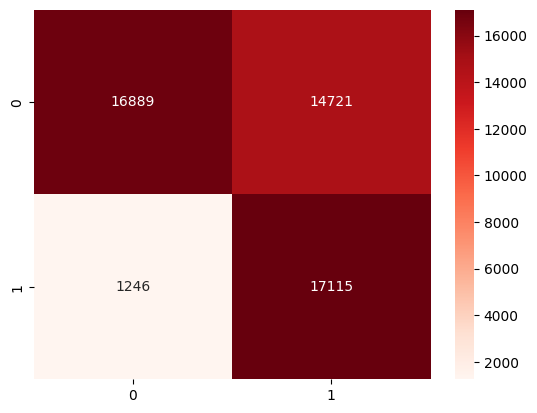

In [56]:
matriz_confusao_equilibrada_2 = confusion_matrix(y_teste, y_predicao_probabilistica_equilibrada_2)
sns.heatmap(matriz_confusao_equilibrada_2, annot=True, fmt='d', cmap='Reds')

##### 8.2.2. Relatório de Classificação
---

In [57]:
relatorio_classificacao_equilibrado_2 = classification_report(y_teste, y_predicao_probabilistica_equilibrada_2)
print(relatorio_classificacao_equilibrado_2)

              precision    recall  f1-score   support

         0.0       0.93      0.53      0.68     31610
         1.0       0.54      0.93      0.68     18361

    accuracy                           0.68     49971
   macro avg       0.73      0.73      0.68     49971
weighted avg       0.79      0.68      0.68     49971



## F) Comparando os Modelos Campeões
---

## 1. Desempenho dos modelos
---

In [58]:
print('\nComparação entre os modelos campeões a partir de Precision, Recall e F1-Score das Classes 0 e 1:\n')

print('\n1. MODELO CAMPEÃO SEM RFE:')
print('\n - Padrão:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_1)
print('\n - Equilibrado:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_equilibrada_1)

print('\n\n2. MODELO CAMPEÃO COM RFE:')
print('\n - Padrão:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_2)
print('\n - Equilibrado:\n')
pm.imprimir_desempenho_modelo(matriz_confusao_equilibrada_2)



Comparação entre os modelos campeões a partir de Precision, Recall e F1-Score das Classes 0 e 1:


1. MODELO CAMPEÃO SEM RFE:

 - Padrão:

O total de predições de teste foi 49971.


 -> Classe 0:
    - Verdadeiro Negativo (TN): há 16584 casos, o que representa, aproximadamente, 33.19% do total de predições de teste.
    - Falso Negativo (FN): há 990 casos, o que representa, aproximadamente, 1.98% do total de predições de teste.

 -> Classe 1:
   - Verdadeiro Positivo (TP): há 17371 casos, o que representa, aproximadamente, 34.76% do total de predições de teste.
   - Falso Positivo (FP): há 15026 casos, o que representa, aproximadamente, 30.07% do total de predições de teste.


 -> Resultados Gerais:
    - A Acurácia total do modelo se dá por: (tp + tn) / total. Seu valor é 0.6795.
    - A quantidade de vezes que o modelo acertou é expressa por TN + TP e é igual a 33955, de um total de 49971. Corresponde a, aproximadamente, 67.95% das predições.
    - A quantidade de vezes que o modelo

## 2. Diferenças entre os desempenhos
---

In [59]:
# Modelo campeão sem RFE
dados_modelo_1 = pm.extracao_desempenho_modelo(matriz_confusao_1)
dados_modelo_equilibrado_1 = pm.extracao_desempenho_modelo(matriz_confusao_equilibrada_1)

# Modelo campeão com RFE
dados_modelo_2 = pm.extracao_desempenho_modelo(matriz_confusao_2)
dados_modelo_equilibrado_2 = pm.extracao_desempenho_modelo(matriz_confusao_equilibrada_2)

# Total de registros
total_registros = dados_modelo_1['tn'] + dados_modelo_1['tp'] + dados_modelo_1['fn'] + dados_modelo_1['fp']

In [64]:
print('A) As diferenças métricas entre os modelos são:\n')
print('Nota: Valores de diferença ou percentual positivos indicam que o primeiro modelo/limiar apresenta resultados maiores que o segundo. Valores negativos indicam o oposto (o segundo termo possui valores maiores).')

print('\n1. Limiar Padrão (0.5):')
print('\n - Métricas Básicas:')
print(f'    TN: Sem RFE - {dados_modelo_1["tn"]} | Com RFE - {dados_modelo_2["tn"]} -> Diferença de {dados_modelo_1["tn"] - dados_modelo_2["tn"]} ou {pm.calcular_percentual((dados_modelo_1["tn"] - dados_modelo_2["tn"]), total_registros):.2f}%')
print(f'    TP: Sem RFE - {dados_modelo_1["tp"]} | Com RFE - {dados_modelo_2["tp"]} -> Diferença de {dados_modelo_1["tp"] - dados_modelo_2["tp"]} ou {pm.calcular_percentual((dados_modelo_1["tp"] - dados_modelo_2["tp"]), total_registros):.2f}%')
print(f'    FN: Sem RFE - {dados_modelo_1["fn"]} | Com RFE - {dados_modelo_2["fn"]} -> Diferença de {dados_modelo_1["fn"] - dados_modelo_2["fn"]} ou {pm.calcular_percentual((dados_modelo_1["fn"] - dados_modelo_2["fn"]), total_registros):.2f}%')
print(f'    FP: Sem RFE - {dados_modelo_1["fp"]} | Com RFE - {dados_modelo_2["fp"]} -> Diferença de {dados_modelo_1["fp"] - dados_modelo_2["fp"]} ou {pm.calcular_percentual((dados_modelo_1["fp"] - dados_modelo_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Sem RFE - {dados_modelo_1["accuracy"]} | Com RFE - {dados_modelo_2["accuracy"]} -> Diferença de {round(dados_modelo_1["accuracy"] - dados_modelo_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_1["accuracy"] - dados_modelo_2["accuracy"], 1):.2f}%')

print('\n - Classe 0:')
print(f'    Recall: Sem RFE - {dados_modelo_1["classe_0"]["recall"]} | Com RFE - {dados_modelo_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_0"]["recall"] - dados_modelo_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["recall"] - dados_modelo_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Precision: Sem RFE - {dados_modelo_1["classe_0"]["precision"]} | Com RFE - {dados_modelo_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_0"]["precision"] - dados_modelo_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["precision"] - dados_modelo_2["classe_0"]["precision"], 1):.2f}%')
print(f'    F1-Score: Sem RFE - {dados_modelo_1["classe_0"]["f1_score"]} | Com RFE - {dados_modelo_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_2["classe_0"]["f1_score"], 1):.2f}%')

print('\n - Classe 1:')
print(f'    Recall: Sem RFE - {dados_modelo_1["classe_1"]["recall"]} | Com RFE - {dados_modelo_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_1"]["recall"] - dados_modelo_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["recall"] - dados_modelo_2["classe_1"]["recall"], 1):.2f}%')
print(f'    Precision: Sem RFE - {dados_modelo_1["classe_1"]["precision"]} | Com RFE - {dados_modelo_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_1"]["precision"] - dados_modelo_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["precision"] - dados_modelo_2["classe_1"]["precision"], 1):.2f}%')
print(f'    F1-Score: Sem RFE - {dados_modelo_1["classe_1"]["f1_score"]} | Com RFE - {dados_modelo_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_2["classe_1"]["f1_score"], 1):.2f}%')

print('\n2. Limiar Equilibrado:')
print('\n - Métricas Básicas:')
print(f'    TN: Sem RFE - {dados_modelo_equilibrado_1["tn"]} | Com RFE - {dados_modelo_equilibrado_2["tn"]} -> Diferença de {dados_modelo_equilibrado_1["tn"] - dados_modelo_equilibrado_2["tn"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["tn"] - dados_modelo_equilibrado_2["tn"]), total_registros):.2f}%')
print(f'    TP: Sem RFE - {dados_modelo_equilibrado_1["tp"]} | Com RFE - {dados_modelo_equilibrado_2["tp"]} -> Diferença de {dados_modelo_equilibrado_1["tp"] - dados_modelo_equilibrado_2["tp"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["tp"] - dados_modelo_equilibrado_2["tp"]), total_registros):.2f}%')
print(f'    FN: Sem RFE - {dados_modelo_equilibrado_1["fn"]} | Com RFE - {dados_modelo_equilibrado_2["fn"]} -> Diferença de {dados_modelo_equilibrado_1["fn"] - dados_modelo_equilibrado_2["fn"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["fn"] - dados_modelo_equilibrado_2["fn"]), total_registros):.2f}%')
print(f'    FP: Sem RFE - {dados_modelo_equilibrado_1["fp"]} | Com RFE - {dados_modelo_equilibrado_2["fp"]} -> Diferença de {dados_modelo_equilibrado_1["fp"] - dados_modelo_equilibrado_2["fp"]} ou {pm.calcular_percentual((dados_modelo_equilibrado_1["fp"] - dados_modelo_equilibrado_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Sem RFE - {dados_modelo_equilibrado_1["accuracy"]} | Com RFE - {dados_modelo_equilibrado_2["accuracy"]} -> Diferença de {round(dados_modelo_equilibrado_1["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 1):.2f}%')

print('\n - Classe 0:')
print(f'    Recall: Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["recall"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Precision: Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["precision"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 1):.2f}%')
print(f'    F1-Score: Sem RFE - {dados_modelo_equilibrado_1["classe_0"]["f1_score"]} | Com RFE - {dados_modelo_equilibrado_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 1):.2f}%')

print('\n - Classe 1:')
print(f'    Recall: Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["recall"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 1):.2f}%')
print(f'    Precision: Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["precision"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 1):.2f}%')
print(f'    F1-Score: Sem RFE - {dados_modelo_equilibrado_1["classe_1"]["f1_score"]} | Com RFE - {dados_modelo_equilibrado_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_equilibrado_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_equilibrado_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 1):.2f}%')

print('\n\nAs diferenças métricas entre os limiares dos modelos são:\n')
print('\nB) Modelo sem RFE:')
print(f'    TN: Padrão - {dados_modelo_1["tn"]} | Equilibrado - {dados_modelo_equilibrado_1["tn"]} -> Diferença de {dados_modelo_1["tn"] - dados_modelo_equilibrado_1["tn"]} ou {pm.calcular_percentual((dados_modelo_1["tn"] - dados_modelo_equilibrado_1["tn"]), total_registros):.2f}%')
print(f'    TP: Padrão - {dados_modelo_1["tp"]} | Equilibrado - {dados_modelo_equilibrado_1["tp"]} -> Diferença de {dados_modelo_1["tp"] - dados_modelo_equilibrado_1["tp"]} ou {pm.calcular_percentual((dados_modelo_1["tp"] - dados_modelo_equilibrado_1["tp"]), total_registros):.2f}%')
print(f'    FN: Padrão - {dados_modelo_1["fn"]} | Equilibrado - {dados_modelo_equilibrado_1["fn"]} -> Diferença de {dados_modelo_1["fn"] - dados_modelo_equilibrado_1["fn"]} ou {pm.calcular_percentual((dados_modelo_1["fn"] - dados_modelo_equilibrado_1["fn"]), total_registros):.2f}%')
print(f'    FP: Padrão - {dados_modelo_1["fp"]} | Equilibrado - {dados_modelo_equilibrado_1["fp"]} -> Diferença de {dados_modelo_1["fp"] - dados_modelo_equilibrado_1["fp"]} ou {pm.calcular_percentual((dados_modelo_1["fp"] - dados_modelo_equilibrado_1["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Padrão - {dados_modelo_1["accuracy"]} | Equilibrado - {dados_modelo_equilibrado_1["accuracy"]} -> Diferença de {round(dados_modelo_1["accuracy"] - dados_modelo_equilibrado_1["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_1["accuracy"] - dados_modelo_equilibrado_1["accuracy"], 1):.2f}%')

print('\n - Classe 0:')
print(f'    Recall: Padrão - {dados_modelo_1["classe_0"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_0"]["recall"] - dados_modelo_equilibrado_1["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["recall"] - dados_modelo_equilibrado_1["classe_0"]["recall"], 1):.2f}%')
print(f'    Precision: Padrão - {dados_modelo_1["classe_0"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_0"]["precision"] - dados_modelo_equilibrado_1["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["precision"] - dados_modelo_equilibrado_1["classe_0"]["precision"], 1):.2f}%')
print(f'    F1-Score: Padrão - {dados_modelo_1["classe_0"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_1["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_0"]["f1_score"] - dados_modelo_equilibrado_1["classe_0"]["f1_score"], 1):.2f}%')

print('\n - Classe 1:')
print(f'    Recall: Padrão - {dados_modelo_1["classe_1"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_1["classe_1"]["recall"] - dados_modelo_equilibrado_1["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["recall"] - dados_modelo_equilibrado_1["classe_1"]["recall"], 1):.2f}%')
print(f'    Precision: Padrão - {dados_modelo_1["classe_1"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_1["classe_1"]["precision"] - dados_modelo_equilibrado_1["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["precision"] - dados_modelo_equilibrado_1["classe_1"]["precision"], 1):.2f}%')
print(f'    F1-Score: Padrão - {dados_modelo_1["classe_1"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_1["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_1["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_1["classe_1"]["f1_score"] - dados_modelo_equilibrado_1["classe_1"]["f1_score"], 1):.2f}%')

print('\nC) Modelo com RFE:')
print('\n - Métricas Básicas:')
print(f'    TN: Padrão - {dados_modelo_2["tn"]} | Equilibrado - {dados_modelo_equilibrado_2["tn"]} -> Diferença de {dados_modelo_2["tn"] - dados_modelo_equilibrado_2["tn"]} ou {pm.calcular_percentual((dados_modelo_2["tn"] - dados_modelo_equilibrado_2["tn"]), total_registros):.2f}%')
print(f'    TP: Padrão - {dados_modelo_2["tp"]} | Equilibrado - {dados_modelo_equilibrado_2["tp"]} -> Diferença de {dados_modelo_2["tp"] - dados_modelo_equilibrado_2["tp"]} ou {pm.calcular_percentual((dados_modelo_2["tp"] - dados_modelo_equilibrado_2["tp"]), total_registros):.2f}%')
print(f'    FN: Padrão - {dados_modelo_2["fn"]} | Equilibrado - {dados_modelo_equilibrado_2["fn"]} -> Diferença de {dados_modelo_2["fn"] - dados_modelo_equilibrado_2["fn"]} ou {pm.calcular_percentual((dados_modelo_2["fn"] - dados_modelo_equilibrado_2["fn"]), total_registros):.2f}%')
print(f'    FP: Padrão - {dados_modelo_2["fp"]} | Equilibrado - {dados_modelo_equilibrado_2["fp"]} -> Diferença de {dados_modelo_2["fp"] - dados_modelo_equilibrado_2["fp"]} ou {pm.calcular_percentual((dados_modelo_2["fp"] - dados_modelo_equilibrado_2["fp"]), total_registros):.2f}%')

print('\n - Acurácia Geral do Modelo:')
print(f'    Acurácia: Padrão - {dados_modelo_2["accuracy"]} | Equilibrado - {dados_modelo_equilibrado_2["accuracy"]} -> Diferença de {round(dados_modelo_2["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 4)} ou {pm.calcular_percentual(dados_modelo_2["accuracy"] - dados_modelo_equilibrado_2["accuracy"], 1):.2f}%')

print('\n - Classe 0:')
print(f'    Recall: Padrão - {dados_modelo_2["classe_0"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["recall"]} -> Diferença de {round(dados_modelo_2["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["recall"] - dados_modelo_equilibrado_2["classe_0"]["recall"], 1):.2f}%')
print(f'    Precision: Padrão - {dados_modelo_2["classe_0"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["precision"]} -> Diferença de {round(dados_modelo_2["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["precision"] - dados_modelo_equilibrado_2["classe_0"]["precision"], 1):.2f}%')
print(f'    F1-Score: Padrão - {dados_modelo_2["classe_0"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_0"]["f1_score"]} -> Diferença de {round(dados_modelo_2["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_0"]["f1_score"] - dados_modelo_equilibrado_2["classe_0"]["f1_score"], 1):.2f}%')

print('\n - Classe 1:')
print(f'    Recall: Padrão - {dados_modelo_2["classe_1"]["recall"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["recall"]} -> Diferença de {round(dados_modelo_2["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["recall"] - dados_modelo_equilibrado_2["classe_1"]["recall"], 1):.2f}%')
print(f'    Precision: Padrão - {dados_modelo_2["classe_1"]["precision"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["precision"]} -> Diferença de {round(dados_modelo_2["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["precision"] - dados_modelo_equilibrado_2["classe_1"]["precision"], 1):.2f}%')
print(f'    F1-Score: Padrão - {dados_modelo_2["classe_1"]["f1_score"]} | Equilibrado - {dados_modelo_equilibrado_2["classe_1"]["f1_score"]} -> Diferença de {round(dados_modelo_2["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 4)} ou {pm.calcular_percentual(dados_modelo_2["classe_1"]["f1_score"] - dados_modelo_equilibrado_2["classe_1"]["f1_score"], 1):.2f}%')

A) As diferenças métricas entre os modelos são:

Nota: Valores de diferença ou percentual positivos indicam que o primeiro modelo/limiar apresenta resultados maiores que o segundo. Valores negativos indicam o oposto (o segundo termo possui valores maiores).

1. Limiar Padrão (0.5):

 - Métricas Básicas:
    TN: Sem RFE - 16584 | Com RFE - 16896 -> Diferença de -312 ou -0.62%
    TP: Sem RFE - 17371 | Com RFE - 17099 -> Diferença de 272 ou 0.54%
    FN: Sem RFE - 990 | Com RFE - 1262 -> Diferença de -272 ou -0.54%
    FP: Sem RFE - 15026 | Com RFE - 14714 -> Diferença de 312 ou 0.62%

 - Acurácia Geral do Modelo:
    Acurácia: Sem RFE - 0.6795 | Com RFE - 0.6803 -> Diferença de -0.0008 ou -0.08%

 - Classe 0:
    Recall: Sem RFE - 0.5246 | Com RFE - 0.5345 -> Diferença de -0.0099 ou -0.99%
    Precision: Sem RFE - 0.9437 | Com RFE - 0.9305 -> Diferença de 0.0132 ou 1.32%
    F1-Score: Sem RFE - 0.6744 | Com RFE - 0.679 -> Diferença de -0.0046 ou -0.46%

 - Classe 1:
    Recall: Sem RFE 

## G) Análises:
---

É sugerido, pelos dados e métricas de desempenho dos modelos de Regressão Logística apresentados, que estes não são adequados para essa base de dados sozinhos.

De todos os modelos selecionados, Regressão Logística tem os piores resultados, com as curvas ROC-AUC e Precision-Recall mais distorcidas, além de haver poucas diferenças entre os modelos campeões, em termos de desempenho, quando se nota os percentuais de diferença.

Há a ideia de trazer o modelo RFE para um ensamble de stacking junto com XGBoost e MLPs para testes. É possível que o cenário da Regressão Logística mude dessa forma e seja um bom adendo a essa parceria.  

## H) Persisitindo os Modelos
---

### 1. Primeiro modelo - Modelo campeão, sem RFE
---

In [61]:
joblib.dump(modelo_campeao, '../persistencia/modelos_persistentes/regressao_logistica/rl_c.pkl')

['../persistencia/modelos_persistentes/regressao_logistica/rl_c.pkl']

### 2. Segundo modelo - Modelo campeão, com RFE
---

In [62]:
joblib.dump(modelo_campeao_rfe, '../persistencia/modelos_persistentes/regressao_logistica/rl_c_rfe.pkl')

['../persistencia/modelos_persistentes/regressao_logistica/rl_c_rfe.pkl']